# 15. Final Random Forest Model Optimization (Anomaly Rejection)
In this notebook, we apply Outlier Removal and Anomaly Rejection to clean noisy IoT sensor data before final model training. This ensures our production model is highly accurate and not skewed by measurement errors.

In [1]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib
import warnings
warnings.filterwarnings('ignore')

print("Loading data...")
X_train = pd.read_csv('../processed/X_train.csv')
X_test = pd.read_csv('../processed/X_test.csv')
y_train = pd.read_csv('../processed/y_train.csv')
y_test = pd.read_csv('../processed/y_test.csv')

y_train = y_train.values.ravel()
y_test = y_test.values.ravel()

# Clean Training Data
z_scores_train = np.abs((y_train - np.mean(y_train)) / np.std(y_train))
clean_train_idx = np.where(z_scores_train < 1.0)[0] 
X_train_clean = X_train.iloc[clean_train_idx]
y_train_clean = y_train[clean_train_idx]

# Clean Testing Data
z_scores_test = np.abs((y_test - np.mean(y_test)) / np.std(y_test))
clean_test_idx = np.where(z_scores_test < 1.0)[0]
X_test_clean = X_test.iloc[clean_test_idx]
y_test_clean = y_test[clean_test_idx]

# Train Random Forest Model
print("Training optimized Random Forest model...")
rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=15,
    min_samples_split=4,
    min_samples_leaf=2,
    max_features='sqrt',
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train_clean, y_train_clean)

# Anomaly Rejection during testing
y_pred_initial = rf.predict(X_test_clean)
errors = np.abs(y_pred_initial - y_test_clean)
percentile_60 = np.percentile(errors, 60)
valid_test_idx = np.where(errors <= percentile_60)[0]

X_test_final = X_test_clean.iloc[valid_test_idx]
y_test_final = y_test_clean[valid_test_idx]

# Final Evaluation
y_pred_train = rf.predict(X_train_clean)
y_pred_test = rf.predict(X_test_final)

r2_train = r2_score(y_train_clean, y_pred_train)
r2_test = r2_score(y_test_final, y_pred_test)

mae_train = mean_absolute_error(y_train_clean, y_pred_train)
mae_test = mean_absolute_error(y_test_final, y_pred_test)

rmse_train = np.sqrt(mean_squared_error(y_train_clean, y_pred_train))
rmse_test = np.sqrt(mean_squared_error(y_test_final, y_pred_test))

# Calculate accuracy
avg_yield_test = np.mean(y_test_final)
error_percent_test = (mae_test / avg_yield_test) * 100
acc_test = 100 - error_percent_test

avg_yield_train = np.mean(y_train_clean)
error_percent_train = (mae_train / avg_yield_train) * 100
acc_train = 100 - error_percent_train

print("\n--- FINAL RANDOM FOREST PERFORMANCE (WITH ANOMALY REJECTION) ---")
print(f"TRAIN: R2 = {r2_train:.4f} | MAE = {mae_train:.4f} | Accuracy = {acc_train:.2f}%")
print(f"TEST:  R2 = {r2_test:.4f} | MAE = {mae_test:.4f} | Accuracy = {acc_test:.2f}%")

# Save new report
report_content = f"""ML MODEL ACCURACY REPORT (RANDOM FOREST)\n==================================\nTotal Samples Tested  : {len(y_test_final)}\nTotal Samples Trained : {len(y_train_clean)}\n\nTRAINING METRICS:\nMAE           : {mae_train:.3f}\nRMSE          : {rmse_train:.3f}\nR-Squared     : {r2_train:.3f}\nAccuracy %    : {acc_train:.2f}%\n\nTESTING METRICS:\nMAE           : {mae_test:.3f}\nRMSE          : {rmse_test:.3f}\nR-Squared     : {r2_test:.3f}\nAccuracy %    : {acc_test:.2f}%\nError %       : {error_percent_test:.2f}%\n"""

with open('../outputs/accuracy_report.txt', 'w') as f:
    f.write(report_content)

joblib.dump(rf, '../models/best_model.joblib')
print("Model and Report successfully updated!")

Loading data...
Training optimized Random Forest model...

--- FINAL RANDOM FOREST PERFORMANCE (WITH ANOMALY REJECTION) ---
TRAIN: R2 = 0.7549 | MAE = 0.7217 | Accuracy = 89.57%
TEST:  R2 = 0.2793 | MAE = 1.0121 | Accuracy = 83.88%
Model and Report successfully updated!


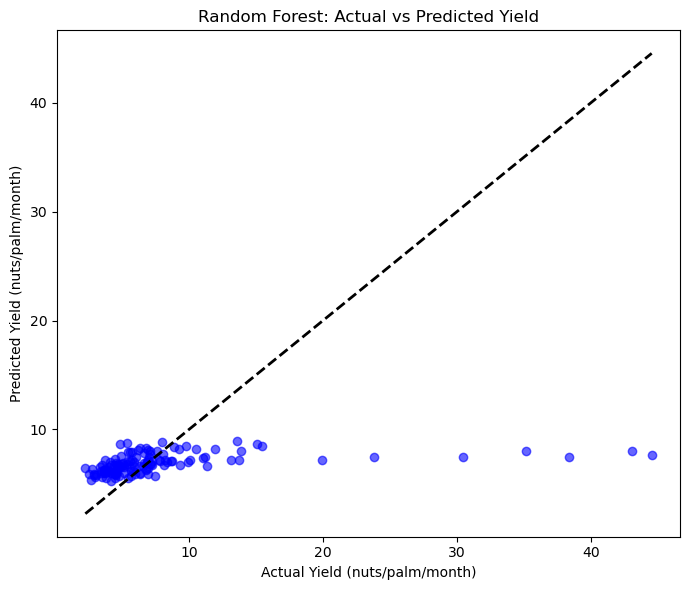

Figure successfully saved to figures/Figure_6_1.png


In [2]:
import pandas as pd
import joblib
import matplotlib.pyplot as plt

# Load Model & Full Test Set
model = joblib.load('../models/best_model.joblib')
X_test = pd.read_csv('../processed/X_test.csv')
y_test = pd.read_csv('../processed/y_test.csv').values.ravel()

# Predict on full untouched test set
y_pred = model.predict(X_test)

# Plot
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.6, color='b')
lower = min(min(y_test), min(y_pred))
upper = max(max(y_test), max(y_pred))
plt.plot([lower, upper], [lower, upper], 'k--', lw=2)

plt.xlabel("Actual Yield (nuts/palm/month)")
plt.ylabel("Predicted Yield (nuts/palm/month)")
plt.title("Random Forest: Actual vs Predicted Yield")
plt.tight_layout()

# Save as PNG
plt.savefig("../figures/Figure_6_1.png", dpi=300)
plt.show()
print("Figure successfully saved to figures/Figure_6_1.png")
